### <b>Section 0: FlyFinder set up</b>



In [ ]:
#@title Mount google drive

from google.colab import drive
drive.mount('/content/drive')
import os

%cd "/content/drive/"

Mounted at /content/drive
/content/drive


In [ ]:
#@title Install dependencies
!pip install img2pdf
!pip install mpi4py

     |████████████████████████████████| 41 kB 309 kB/s 
     |████████████████████████████████| 2.0 MB 8.6 MB/s 
     |████████████████████████████████| 2.4 MB 5.0 MB/s 
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
    Preparing wheel metadata ... done


In [ ]:
#@title FlyFinder directory location
fly_finder_dir="MyDrive/FlyFinder_v1.0/" #@param {type: "string"}
train_dir="train_4p" #@param {type: "string"}
test_dir="09.21.2021" #@param {type: "string"}


fly_finder_dir+="/"
train_dir+="/"
test_dir+="/"


%cd $fly_finder_dir
%reload_ext rpy2.ipython
!Rscript dependencies.R

/content/drive/MyDrive/FlyFinder_v1.0
installing new packages: please wait ...gridExtra argparseInstalling packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)
also installing the dependency ‘findpython’

trying URL 'https://cran.rstudio.com/src/contrib/findpython_1.0.7.tar.gz'
Content type 'application/x-gzip' length 6925 bytes
downloaded 6925 bytes

trying URL 'https://cran.rstudio.com/src/contrib/gridExtra_2.3.tar.gz'
Content type 'application/x-gzip' length 1062844 bytes (1.0 MB)
downloaded 1.0 MB

trying URL 'https://cran.rstudio.com/src/contrib/argparse_2.1.1.tar.gz'
Content type 'application/x-gzip' length 33002 bytes (32 KB)
downloaded 32 KB

* installing *source* package ‘findpython’ ...
** package ‘findpython’ successfully unpacked and MD5 sums checked
** using staged installation
** R
** byte-compile and prepare package for lazy loading
** help
*** installing help indices
** building package indices
** testing if installed package can be loaded from tempor

### <b>Section 1: Training the classifier</b>

In [ ]:
#@title Importing FlyFinder Function
from FF_utils import *

<a name="l1"></a>
###  1.1. Setting up initial parameters

In [ ]:
#@title The parameters for drawing
# Defining the colors
blue=(0,0,255); 
red=(255,0,0); 
magenta=(255,0,255); 

# Setting the line, point and figure size
# if pen=5 or less and the bottom lines is not visible, set it to 10
pen=5  #@param {type : "raw"}
point=15 #@param {type : "raw"}
figSize=5 #@param {type : "raw"}

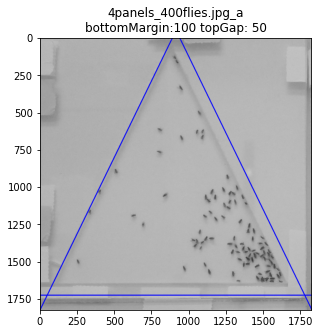

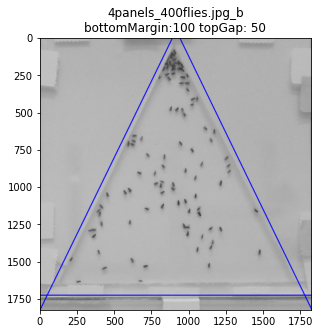

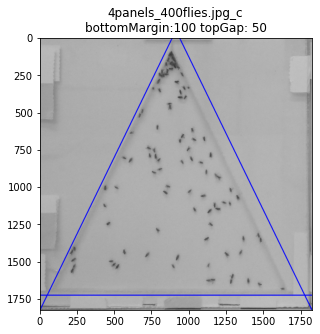

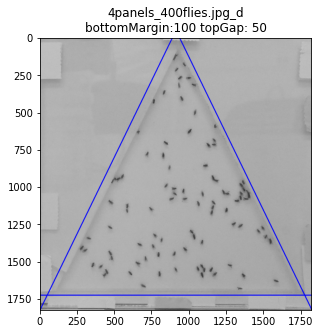

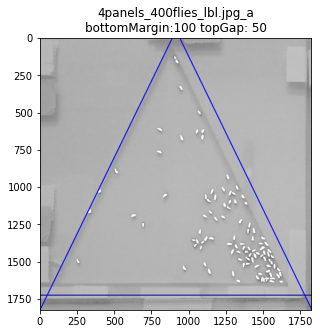

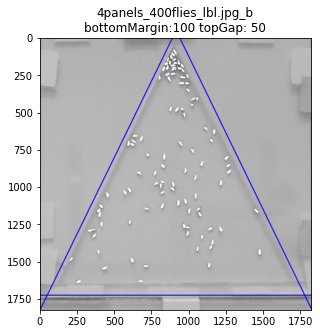

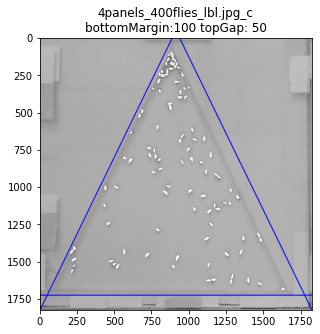

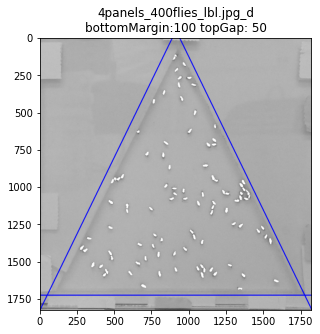

In [ ]:
#@title Cropping the sides, masking the background and visualization for image files for training a model

#Cropping the input image if necessary (pxl)
cropLeft4=0 #@param {type : "raw"}
cropRight4=0 #@param {type : "raw"}
cropTop4=0 #@param {type : "raw"}
cropBottom4=0 #@param {type : "raw"}

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=100 #@param {type : "raw"}
topGap4=50 #@param {type : "raw"}

## Visualization
## imagPath_="train_4p/"
imagPath_=train_dir


displayImages = True #@param {type:"boolean"}

def display_img(booln):
  if booln:
    viewImageMargins4Panel(imagPath=train_dir, bottomMargin=bottomMargin4, 
                           topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, 
                           cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, 
                           figSize=figSize, pen_=pen)

display_img(displayImages)
#viewImageMargins4Panel(imagPath=train_dir, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 

<a name="l2"></a>
### 1.2. Training the random forest classifier

In [ ]:
#@title Training settings and train a machine learning model 

modelName = "test_0915"  #@param {type:"string"}
plateType = "4Panel"  #@param {type:"string"}
nGaussianFilters=40  #@param {type:"raw"}
nMedianFilters=10  #@param {type:"raw"}
nEstimators = 30  #@param {type:"raw"}
bottomMargin = 100  #@param {type:"raw"}
topGap = 50  #@param {type:"raw"}
cropLeft = 0  #@param {type:"raw"}
cropRight = 0  #@param {type:"raw"}
cropTop = 0  #@param {type:"raw"}
cropBottom = 0  #@param {type:"raw"}
runTrainig = False #@param {type:"boolean"}


def train_warpper(modelName, plateType, nGaussianFilters,
                  nMedianFilters, nEstimators, bottomMargin,
                  topGap, cropLeft, cropRight,
                  cropTop, cropBottom, runTrainig
                  ):
  
  cmd = f"! python3 FlyFinder_train.py --modelName {modelName} \
                            --plateType {plateType} \
                            --nGaussianFilters={nGaussianFilters} \
                            --nMedianFilters={nMedianFilters} \
                            --nEstimators {nEstimators} \
                            --bottomMargin {bottomMargin} \
                            --topGap {topGap} \
                            --cropLeft {cropLeft} \
                            --cropRight {cropTop} \
                            --cropTop {cropTop} \
                            --cropBottom {cropBottom} \
                            --inPath {train_dir} "
  if runTrainig:
    # print(cmd)
    os.system(cmd)

train_warpper(modelName, plateType, nGaussianFilters,
                  nMedianFilters, nEstimators, bottomMargin,
                  topGap, cropLeft, cropRight,
                  cropTop, cropBottom, runTrainig)



# ! python FlyFinder_train.py --modelName $modelName \
#                             --plateType $plateType \
#                             --nGaussianFilters=$nGaussianFilters \
#                             --nMedianFilters=$nMedianFilters \
#                             --nEstimators $nEstimators \
#                             --bottomMargin $bottomMargin \
#                             --topGap $topGap \
#                             --cropLeft $cropLeft \
#                             --cropRight $cropTop \
#                             --cropTop $cropTop \
#                             --cropBottom $cropBottom \
#                             --inPath $train_dir 


-* FlyFinder_v1.0 *-


Training a random forest classifier for image segmentation ( 4Panel images) 
----------------------------------------------------------------------------------

Original images:['4panels_400flies.jpg']
Labeled images: ['4panels_400flies_lbl.jpg']
Training set size: 1 files

4panels_400flies.jpg	4panels_400flies_lbl.jpg

  -- Processing panel a --
  (1530709, 51)

  -- Processing panel b --
  (3060606, 51)

  -- Processing panel c --
  (4590382, 51)

  -- Processing panel d --
  (6119344, 51)
 
Dimensions after removing dupliate rows:
 (4892971, 51)
Trainning the RandomForestClassifier, number of estimators =  30 


 Confusion matrix:
[[475598   2271]
 [  2149   9280]]

Accuracy = 0.9909666501804626

Feature_importance:
--------------------
<class 'pandas.core.series.Series'>
 Gaussian_1       0.117959
Median_5          0.114006
Median_7          0.078343
Median_3          0.075047
Median_1          0.070980
 Gaussian_2       0.056721
Median_2          0.051529
M

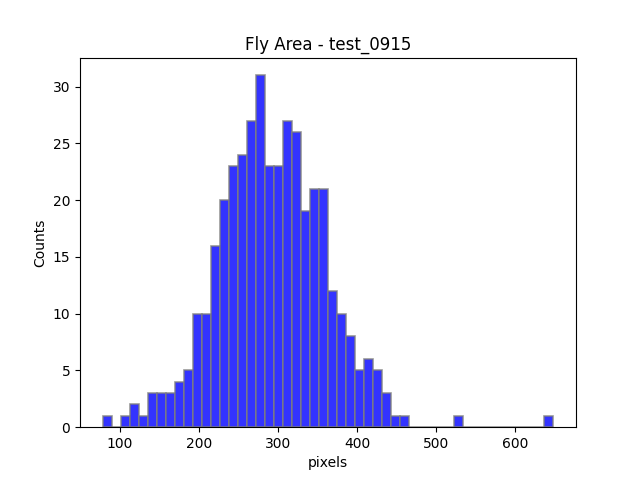

In [ ]:

#@title Viewing the flyArea density plot - optional
from IPython.display import Image

density_png_file = f"RFC_model/{modelName}_flyArea.png"
Image(filename=density_png_file, width=400, height=400)
# Image(filename="RFC_model/google_colab_test_flyArea.png", width=400, height=400)

### <b>Section 2: Segmentation of images</b>

<a name="l3"></a>
### 2.1. Performing the first segmentation 


/content/drive/.shortcut-targets-by-id/1nsfBYinPoi6KsL3Z6GYeXnx1pkAl6QlB/FlyFinder_v1.0/FF_utils.py:204: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  out=plt.figure(figsize = (size,size))


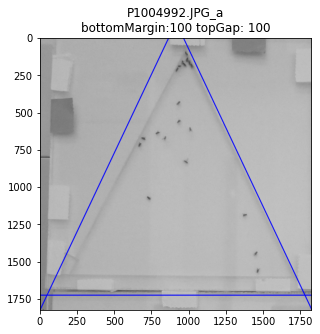

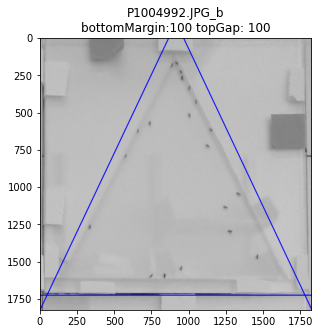

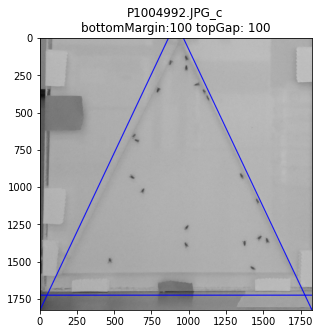

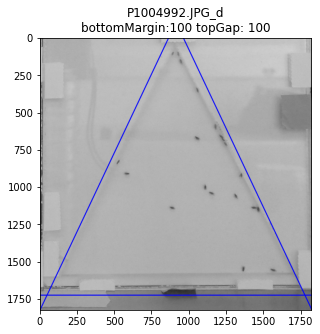

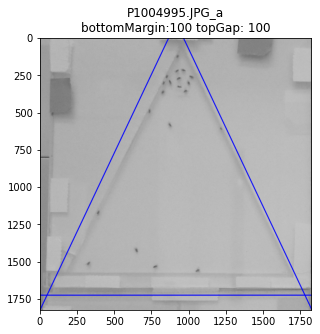

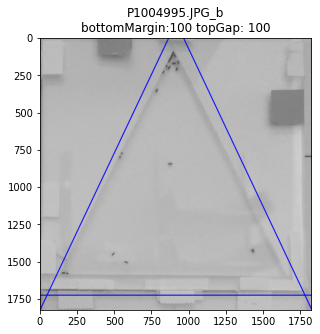

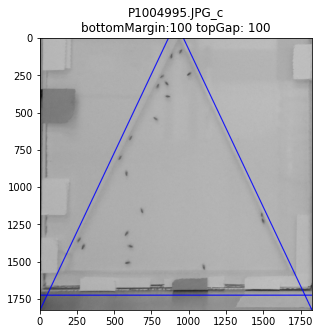

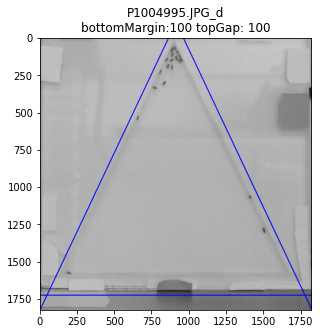

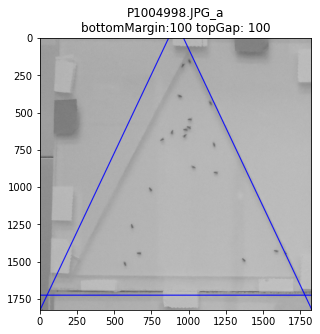

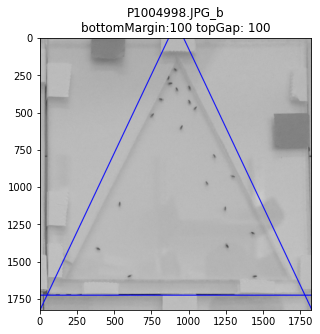

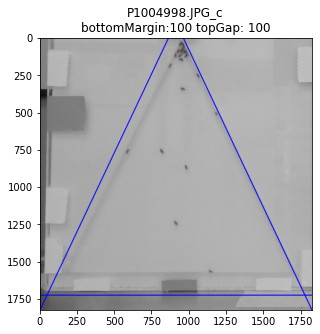

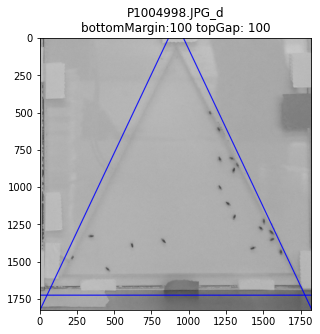

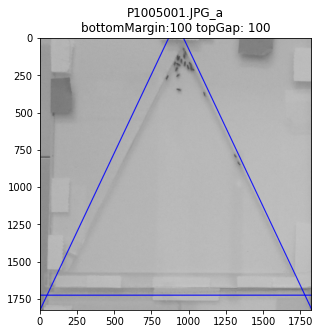

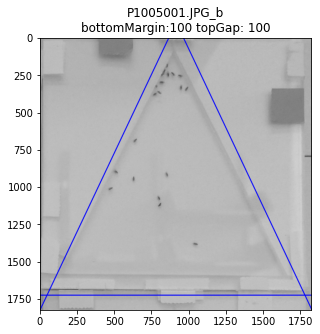

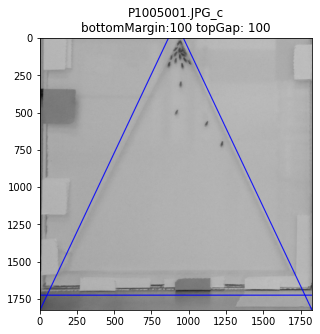

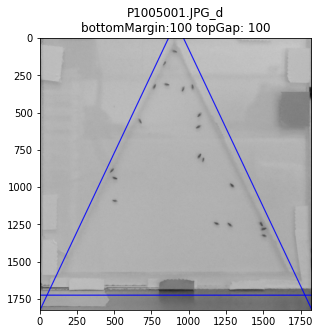

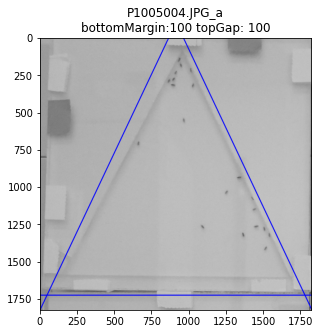

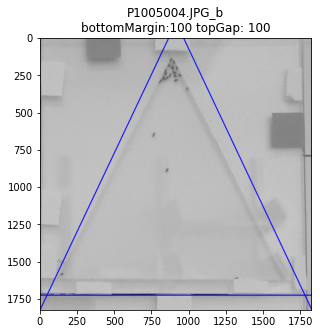

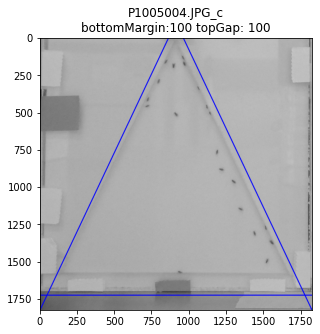

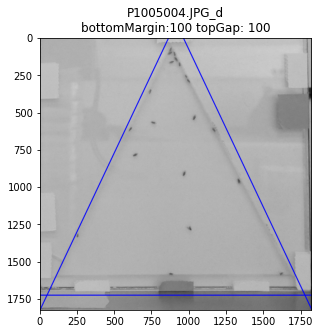

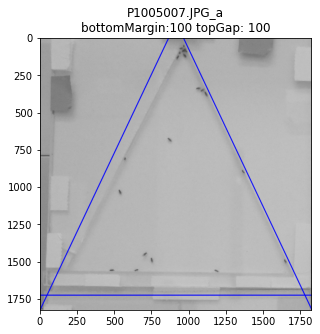

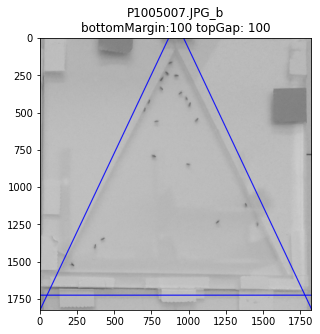

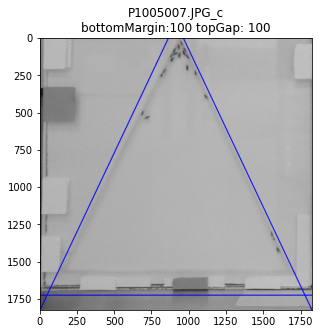

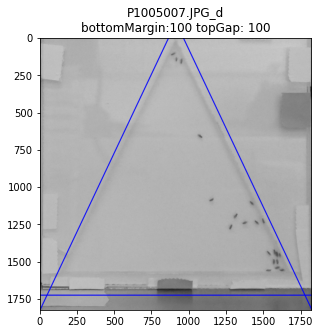

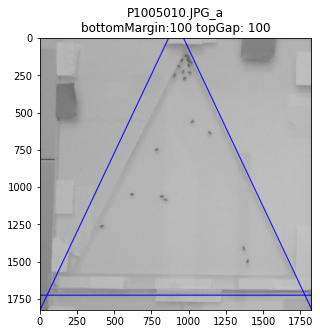

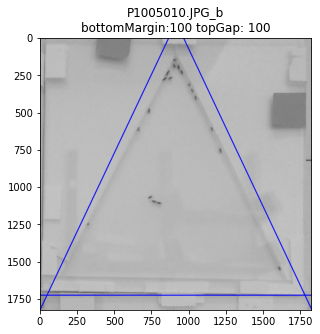

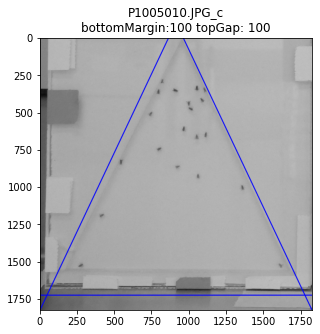

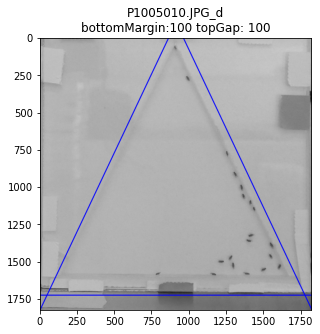

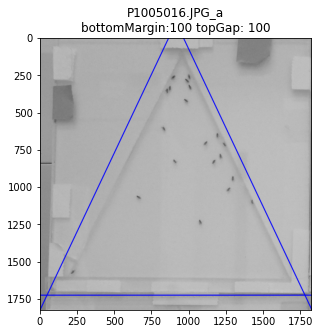

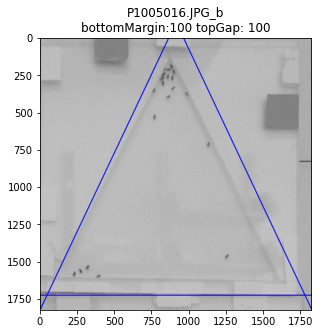

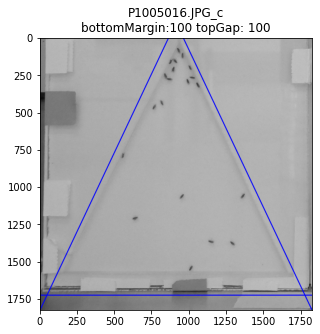

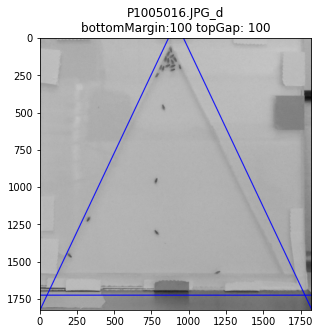

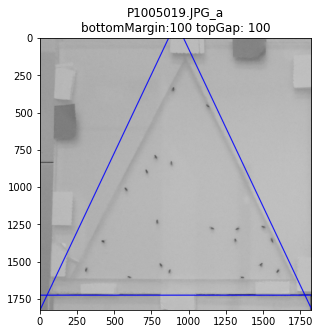

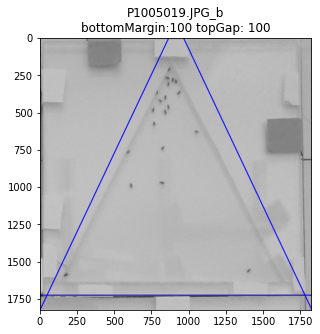

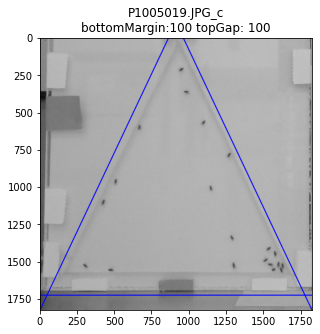

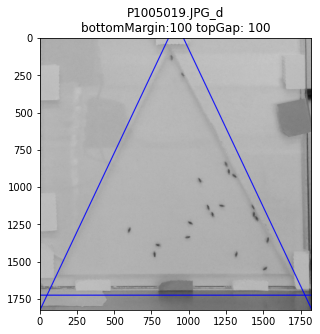

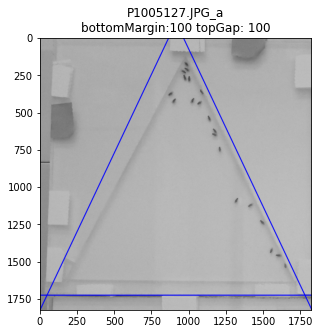

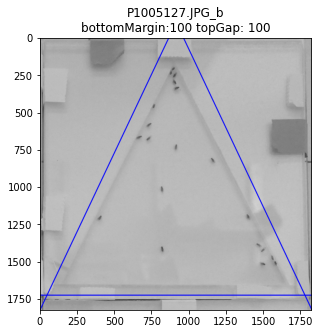

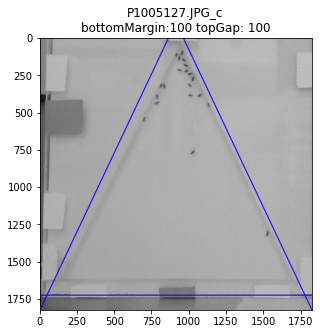

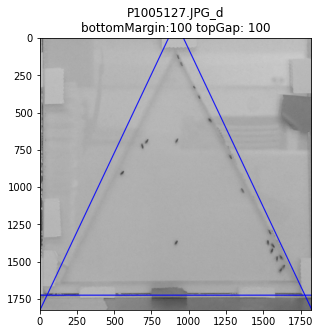

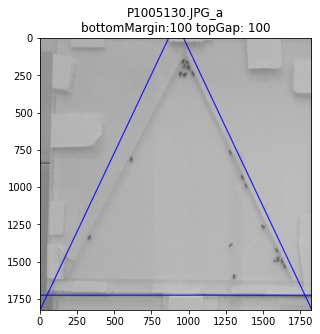

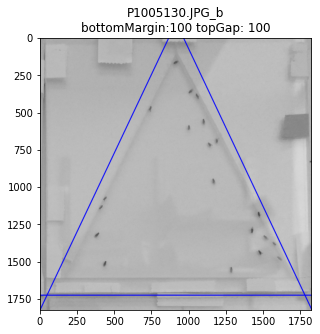

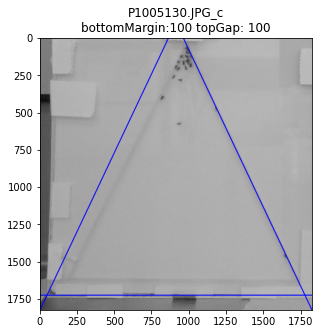

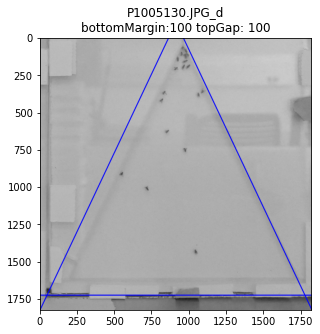

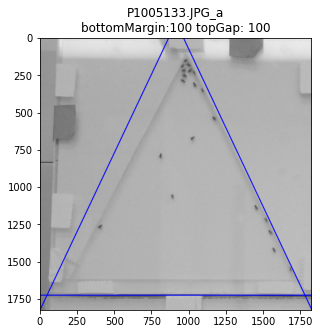

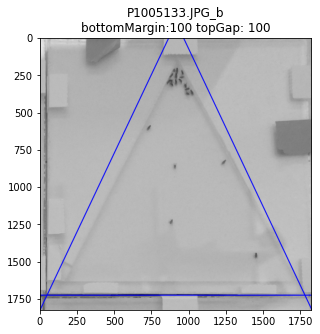

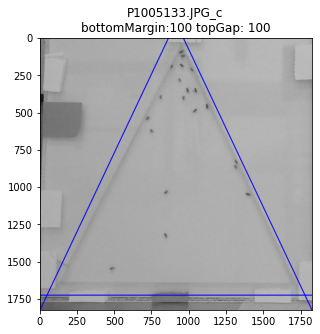

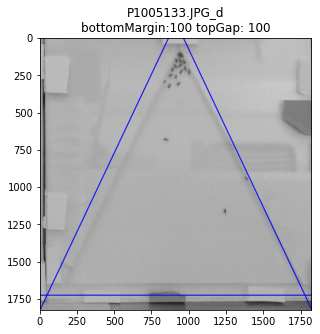

In [ ]:
#@title Cropping the input image if necessary and visualization

cropLeft4=0 #@param {type : "raw"}
cropRight4=0 #@param {type : "raw"}
cropTop4=0 #@param {type : "raw"}
cropBottom4=0 #@param {type : "raw"}

# Applying the mask:
# bottomMargin : correspond to the marging applied to the bottom of the image
# topgap : correspond to the distance between the two sides-triangle lines (at the top of the picture)   

bottomMargin4=100 #@param {type : "raw"}
topGap4=100 #@param {type : "raw"}


displayImages = False #@param {type:"boolean"}

def display_img(booln):
  if booln:
    viewImageMargins4Panel(imagPath=test_dir, bottomMargin=bottomMargin4, 
                           topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, 
                           cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, 
                           figSize=figSize, pen_=pen)

## Visualization
#viewImageMargins4Panel(imagPath=test_dir, bottomMargin=bottomMargin4, topGap=topGap4, cropLeft=cropLeft4, cropRight=cropRight4, cropTop=cropTop4, cropBottom=cropBottom4,  marginCol=blue, figSize=figSize, pen_=pen) 
display_img(displayImages)

In [ ]:
#@title Running the first segmentation
modelName = "M4Panel_GF40_MF10_Es30_mar100_topG50_RFC" #@param {type:"string"}
plateType = "4panel" #@param {type:"string"}
minArea =  70#@param {type:"raw"}
maxArea =  350#@param {type:"raw"}
nGaussianFilters = 40 #@param {type:"raw"}
nMedianFilters = 10 #@param {type:"raw"}
nEstimators = 30 #@param {type:"raw"}
bottomMargin =  200#@param {type:"raw"}
topGap =  150#@param {type:"raw"}
cropLeft = 0 #@param {type:"raw"}
cropRight = 0 #@param {type:"raw"}
cropTop = 0 #@param {type:"raw"}
cropBottom = 0 #@param {type:"raw"}
numFlies =  20#@param {type:"raw"}


! mpiexec --allow-run-as-root -np 2  python FlyFinder_first_segmentation.py --modelName $modelName \
                                                        --plateType $plateType \
                                                        --minArea $minArea \
                                                        --maxArea $maxArea \
                                                        --nGaussianFilters $nGaussianFilters \
                                                        --nMedianFilters $nMedianFilters \
                                                        --bottomMargin $bottomMargin \
                                                        --topGap $topGap \
                                                        --cropLeft $cropLeft \
                                                        --cropRight $cropRight \
                                                        --cropTop $cropTop   \
                                                        --cropBottom $cropBottom \
                                                        --numFlies $numFlies  \
                                                        --inPath $test_dir \


-* FlyFinder_v1.0 *-




*--- Running FlyFinder Random Forest-based segmantation : core n. 00 ---*

-----------------------------------------------------------------------------------------------

Started time: 2021-09-20 15:53:41.034816



Active path : /content/drive/My Drive/FlyFinder_v1.0/08.05.2021/

Settings :
Namespace(bottomMargin=200, cropBottom=0, cropLeft=0, cropRight=0, cropTop=0, inPath='08.05.2021/', maxArea=350, minArea=70, modelName='M4Panel_GF40_MF10_Es30_mar100_topG50_RFC', nGaussianFilters=40, nMedianFilters=10, numFlies=20, plateType='4panel', topGap=150)

Loading the RFC model. Please wait ... 

  Model loaded successfully: /content/drive/My Drive/FlyFinder_v1.0/RFC_model/M4Panel_GF40_MF10_Es30_mar100_topG50_RFC.pkl


  Number of images : 2

['1.JPG', '2.JPG']

1.JPG

 -- Segmenting panel a --
 Generating features, please wait
 Running the randomforest flassifier
 ->Denoising the obtained image
 ** Failed to detect the correct number of flies! Noise cutoff (min fl

##### <a name="l4"></a>
### 2.2. Manual editing the failed images


The output after segmentation contains two directories:<br>
<b>FlyFinder_v1.0/test_4p/out</b> for well segmented images and <b>FlyFinder_v1.0/test_4p/outf</b> for failed images.<br> 
For a quick review of all figures it is recommended to open and check the <b>out.pdf</b> and <b>outf.pdf</b> located in <b>out</b> and <b>outf</b> directories respectively. <br> 

The user must first check for any potential failed images in the out directory and move both the .csv and .jpg files to the <br>
outf directory. All .jpg images in the outf directory must then be manually edited. Editing involves ensuring all flies are <br>
correctly identified by a white 10px by 10px box and background noise (incorrectly labeled white boxes) deleted/blackened. Image<br>
editing can be performed using Fiji or any photo editing software.


<a name="l5"></a>

### 2.3. Performing the second segmentation 

In [ ]:
#@title The second segmentation 
def second_segmentation(test_dir):
  cmd = f"mpiexec -n 4 python3 FlyFinder_second_segmentation.py --inPath {test_dir}/outf"
  os.system(cmd)

# second_segmentation(test_dir)
! mpiexec -n 4 python3 FlyFinder_second_segmentation.py --inPath $test_dir/outf

--------------------------------------------------------------------------
mpiexec has detected an attempt to run as root.
Running at root is *strongly* discouraged as any mistake (e.g., in
defining TMPDIR) or bug can result in catastrophic damage to the OS
file system, leaving your system in an unusable state.

You can override this protection by adding the --allow-run-as-root
option to your cmd line. However, we reiterate our strong advice
against doing so - please do so at your own risk.
--------------------------------------------------------------------------


<a name="l6"></a>
### 2.4. Creating the table of fly coordinates

In [ ]:
#@title Creating the table of fly coordinates (Run this cell)

! python FlyFinder_maketable.py --inPath  $test_dir


* RFC segmantation : Number of tables = 41

p1004992_panel_a_flies_20.csv
p1004992_panel_b_flies_20.csv
p1004992_panel_c_flies_20.csv
p1004992_panel_d_flies_20.csv
p1004995_panel_a_flies_20.csv
p1004995_panel_b_flies_20.csv
p1004995_panel_c_flies_20.csv
p1004998_panel_a_flies_20.csv
p1004998_panel_b_flies_20.csv
p1004998_panel_c_flies_20.csv
p1004998_panel_d_flies_20.csv
p1005001_panel_a_flies_20.csv
p1005001_panel_b_flies_20.csv
p1005001_panel_c_flies_20.csv
p1005001_panel_d_flies_20.csv
p1005004_panel_a_flies_20.csv
p1005004_panel_c_flies_20.csv
p1005004_panel_d_flies_20.csv
p1005007_panel_a_flies_20.csv
p1005007_panel_b_flies_20.csv
p1005007_panel_c_flies_20.csv
p1005007_panel_d_flies_20.csv
p1005010_panel_a_flies_20.csv
p1005010_panel_b_flies_20.csv
p1005010_panel_c_flies_20.csv
p1005010_panel_d_flies_20.csv
p1005016_panel_a_flies_20.csv
p1005016_panel_c_flies_20.csv
p1005016_panel_d_flies_20.csv
p1005019_panel_a_flies_20.csv
p1005019_panel_b_flies_20.csv
p1005019_panel_c_flies_20

<a name="l7"></a>
### 2.5. Calculating the nearest neighbors distances




In [ ]:
#@title Calculating the nearest neighbors distance - Run this cell
imgwidth = 1824 #@param {type:"raw"}
imgheight = 1824 #@param {type:"raw"}

! Rscript Neighbor_distances.R --inPath  $test_dir --imgWidth $imgwidth --imgHeight $imgheight




 * ----  Computing nearest neigbor distance  ---- *

 Path of x-y coordiate table :  test_4p/
 Images width  (pxl) :  1824
 Images hieght (pxl) :  1824
p1004992_panel_a_flies_20.jpg 
p1004992_panel_b_flies_20.jpg 
p1004992_panel_c_flies_20.jpg 
p1004992_panel_d_flies_20.jpg 
p1004995_panel_a_flies_20.jpg 
p1004995_panel_b_flies_20.jpg 
p1004995_panel_c_flies_20.jpg 
p1004998_panel_a_flies_20.jpg 
p1004998_panel_b_flies_20.jpg 
p1004998_panel_c_flies_20.jpg 
p1004998_panel_d_flies_20.jpg 
p1005001_panel_a_flies_20.jpg 
p1005001_panel_b_flies_20.jpg 
p1005001_panel_c_flies_20.jpg 
p1005001_panel_d_flies_20.jpg 
p1005004_panel_a_flies_20.jpg 
p1005004_panel_c_flies_20.jpg 
p1005004_panel_d_flies_20.jpg 
p1005007_panel_a_flies_20.jpg 
p1005007_panel_b_flies_20.jpg 
p1005007_panel_c_flies_20.jpg 
p1005007_panel_d_flies_20.jpg 
p1005010_panel_a_flies_20.jpg 
p1005010_panel_b_flies_20.jpg 
p1005010_panel_c_flies_20.jpg 
p1005010_panel_d_flies_20.jpg 
p1005016_panel_a_flies_20.jpg 
p1005016_

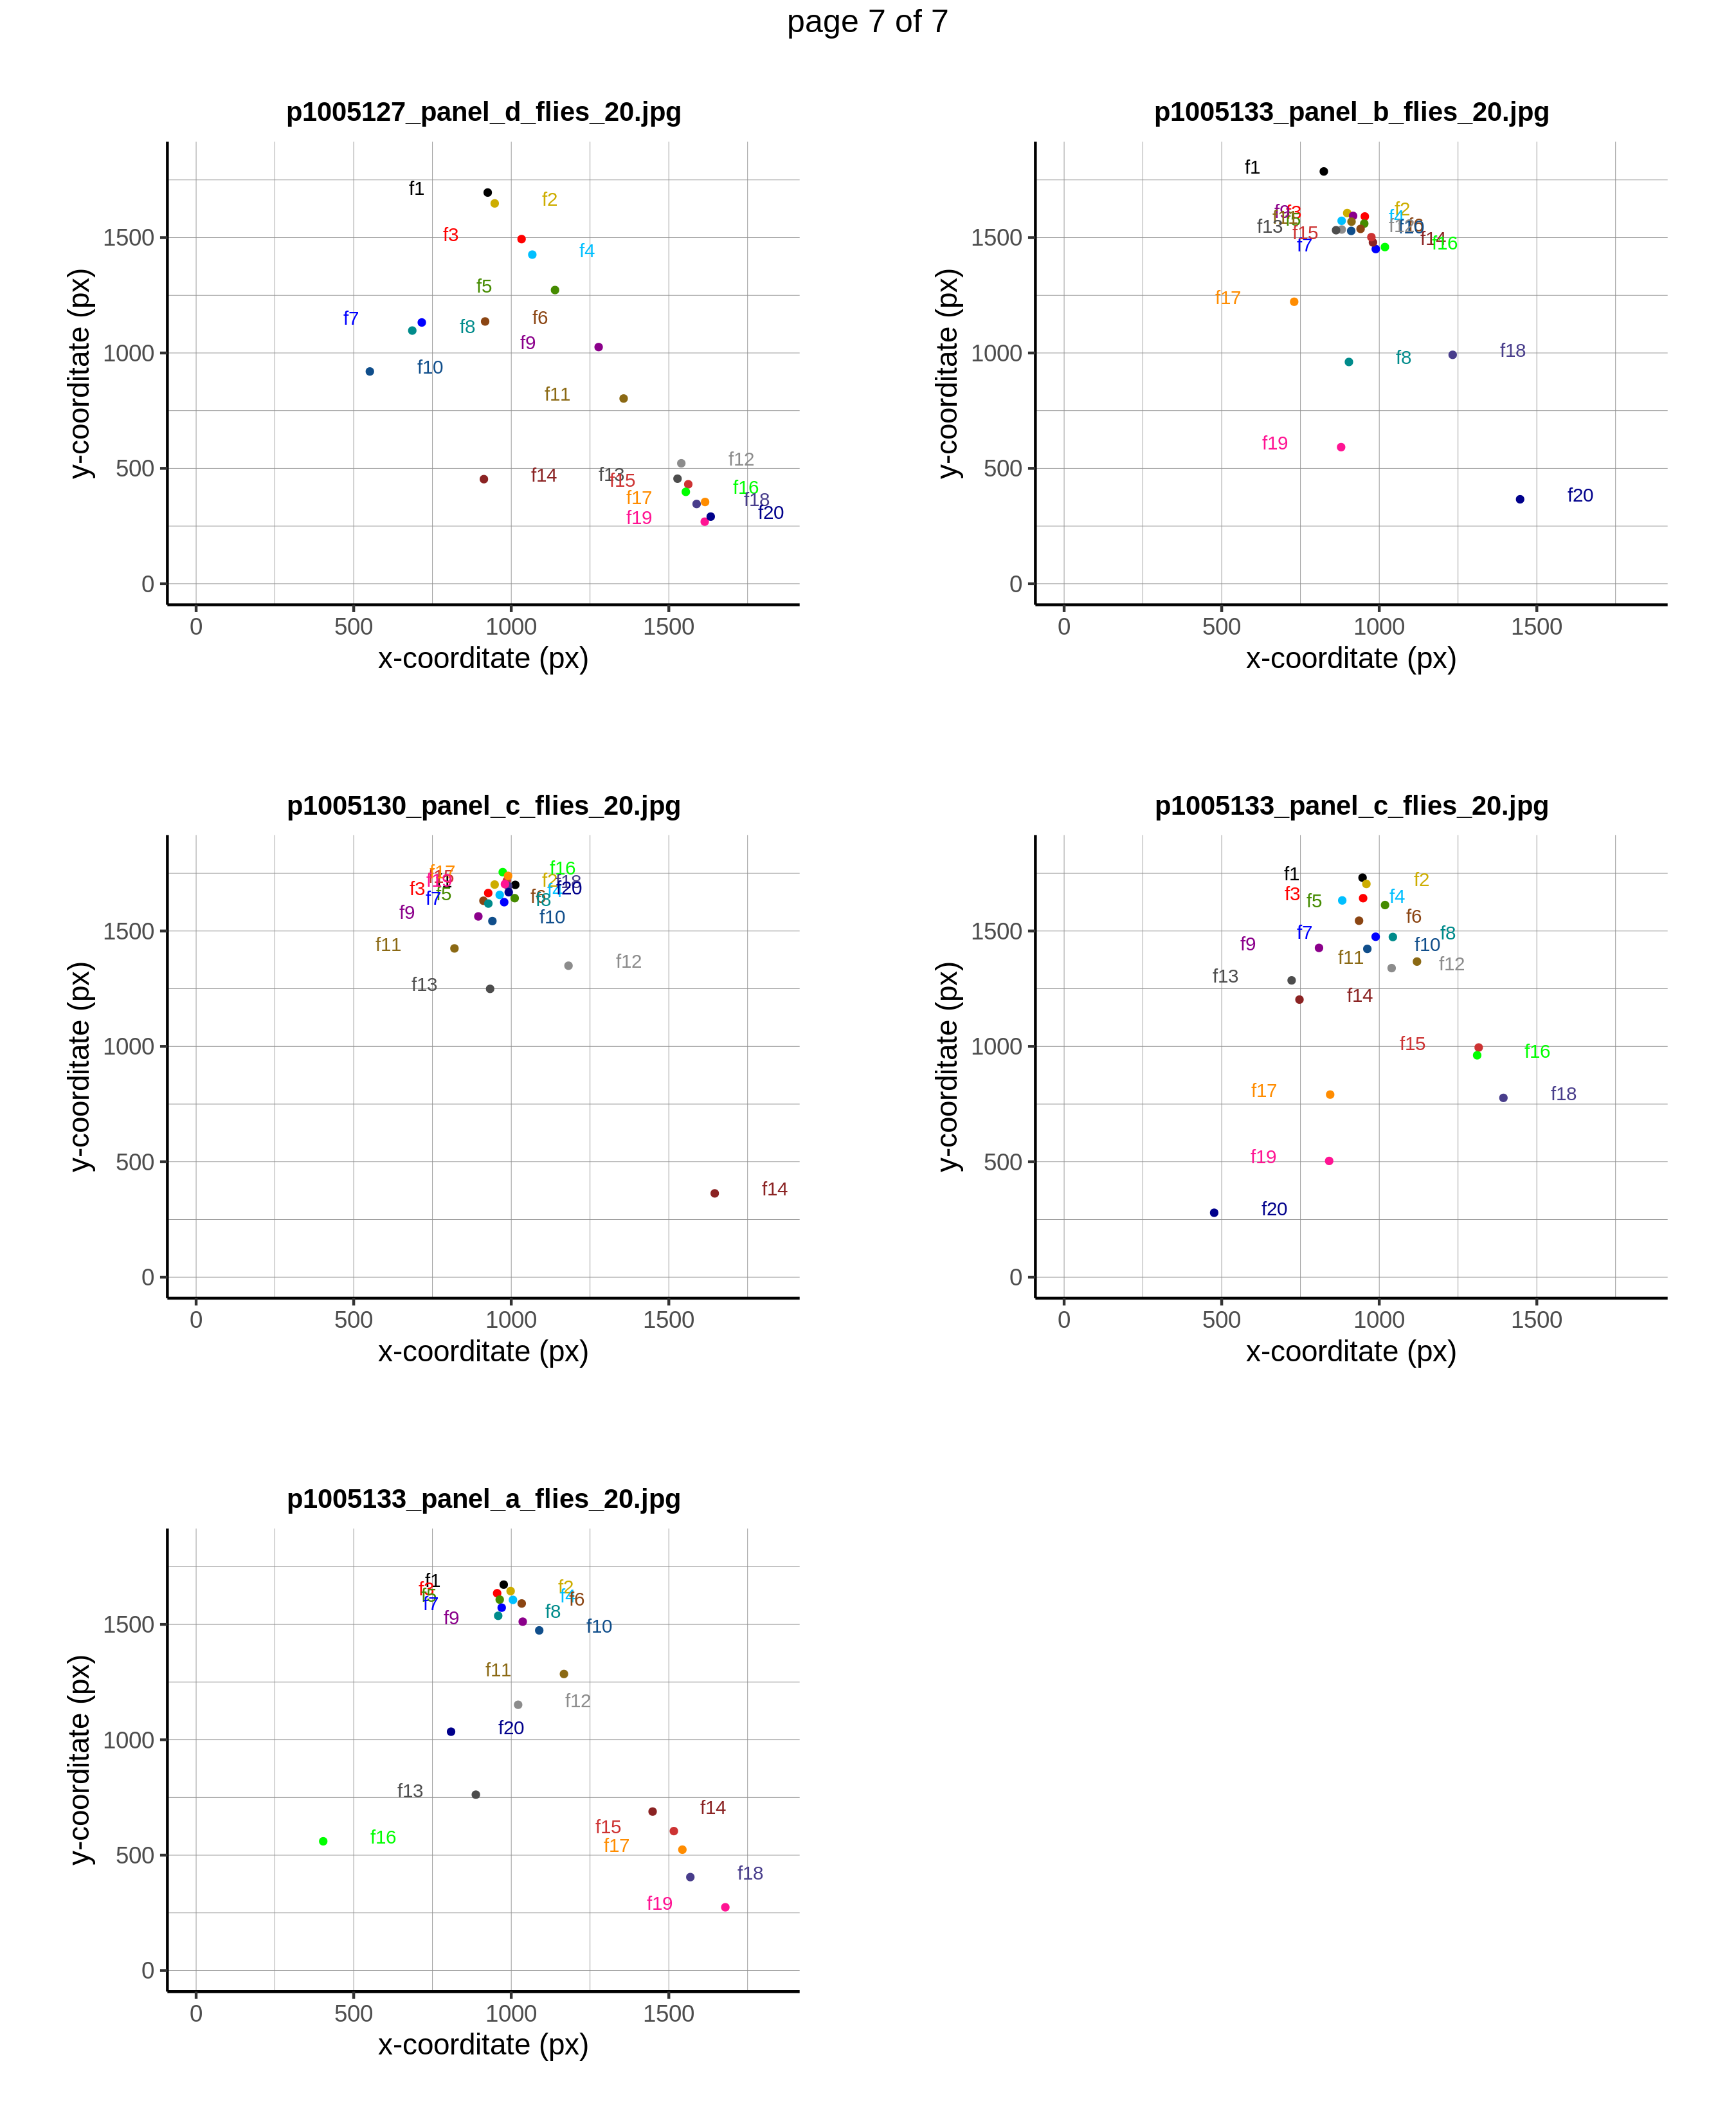

In [ ]:
#@title Displaying the fly coordinate figure

from IPython.display import Image
png_file=f"{test_dir}/FinalFigures.dist.png"
Image(filename=png_file)

###   *   Here ends of the pipeline  *

## FlyFinder version 1.0 (4-panel images - Panasonic Camera )
This notebook provides the sequence of instructions and commands for training a random forest classifer <br>
used during segmentation. It also gives instructions and the commands of the whole process of segmentation.
<br><br>
If the model has been trained for a specific study setup, there will be no need to retrain, the user can <br>
immediately proceed to section 2 for first segmentation.

<u> Used camera model:</u><br>
Panosonic DC-ZS200<br>
<u>Settings</u>:<br> 
Aspect-ration 1:1<br>
Picture size: 3648 X 3648 pxl<br>
Filter settings: monochrome<br>
Use a 10-second self timer for three pictures<br>


# Instructions <a name="Instructions"></a>

---

Quick start
- Upload your image files to train image folder and test image folder in your Google Drive
- Define path to the folders adjust parameters and name your machine learning model
- output files will be available in your test image folder 


---

### Section 1: Training the classifier

- [1.1. Setting up initial parameters](#l1)
   
- [1.2. Training the random forest classifier](#l2)

### Section 2: Segmentation of images
   
- [2.1. Performing the first segmentation](#l3)

- [2.2. Manual editing the failed images ](#l4)

- [2.3. Performing the second segmentation](#l5)

- [2.4. Creating the table of fly coordinates ](#l6)

- [2.5. Calculating the nearest neighbors distances](#l7)
 

<b>  - Cropping the sides, masking the background and visualization (4-panel images): </b><br>
The <b>cropLeft</b>, <b>cropRight</b>, <b>cropTop</b> and <b>cropBottom</b> are used to crop the left, right,<br> 
top and  bottom sides the input images in case it is necessary.<br>
The <b>bottomMargin</b> and <b>topGap</b> parameters are used to demarcate the triangle such that the area inside the <br>
lines will be used while the area outside will be ignored. Different values can be tired to determine the best<br>
fit for a particular imaging setup. The demarcated pictures can be viewed in the next command

After getting the best values of <b>bottomMargin</b> and <b>topGap</b> that best demarcate the <br>
triangle (i.e bottomMargin=60 topGap=10), they will be used to traini either a 1 or 4Panel-based random forest classifier.<br>

We can first see the script parameters like this:

! python FlyFinder_train.py --help

<b>- Check if there are trained models:</b>

! python FlyFinder_train.py models

<b>- Viewing the directory of images used for segmentation: </b><br>
Note: the labelled image for training must have '_lbl' added to its name right before the '.jpg' file extension.

<u>Training settings:</u><br>
plateType = 4Panel (this can be changed to 1Panel if dealing with 1-panel/triangle images)<br>
Number of gaussian filters (nGaussianFilters=40) <br>
Median filters (nMedianFilters=10) <br>
Number of trees (nEstimators=30) <br>
bottomMargin = 100 <br> 
topGap = 50 <br>
cropLeft=0 <br>
cropRight=0 <br>
cropTop=0<br>
cropBottom=0<br>

 Viewing the script parameters of the script that perfroms the first segmentation:

 ! python FlyFinder_first_segmentation.py --help

<b>- Checking the names of trained models: both train and first segmentation scripts can help checking available models:</b><br>
Both <i>FlyFinder_train.py</i> and <i> FlyFinder_first_segmentation.py</i> functions can show trained/available models if passe the 'models' parameter.

! python FlyFinder_train.py models   
! python FlyFinder_first_segmentation.py models

<b>- Checking the content of the input directory:</b><br>
The directory must contain the images in jpeg format. The file name should end with '.jpg' or '.JPG'

<b>- Running the first segmentation script:</b></br>
The script can be run in <u>parallel</u> using the <b>mpiexec</b> command and by specifying the number <br>
of cores (processors) using the <b>-n</b> parameter. The script can also be run in serial using simply the following command:<br>
<i>python FlyFinder_first_segmentation.py {add command line arguments} </i>
<br><br>

Viewing the output after post-procesing. Directory FlyFinderV2.0/test_4p/outf/out_ps

! ls $test_dir/outf/out_ps

An R command computes the first, second, third and average nearest neighbor distances, compiling them into final tables and figures.<br>
It is required to specify the image width <b>imgWidht</b> and images hieght <b>imgHeight</b><br>
In this case it s 3648 pxl / 2 = 1824 pxl i.e the lenght of a side of each of the 4 panels.
